# Module project: build a variational autoencoder for digits

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-3-mnist-vae.ipynb`, attached to this lesson and saved on your device with the course. It builds and runs the whole project. Open it in one click in Google Colab (free, nothing to install): [Open in Colab](https://colab.research.google.com/github/mahmoudyosrimahmoud13/inpace-library/blob/main/courses/bishop-dl-5-generative/files/project-3-mnist-vae.ipynb). Or open the saved copy on your device with Jupyter or VS Code.
- **Finished code**: the `projects/mnist-vae` folder in the course files, to check your work.
- **Data**: MNIST handwritten digits (Hugging Face: ylecun/mnist). Source: [https://huggingface.co/datasets/ylecun/mnist](https://huggingface.co/datasets/ylecun/mnist) · about: [http://yann.lecun.com/exdb/mnist/](http://yann.lecun.com/exdb/mnist/) · licence: CC BY-SA 3.0. `data.py` downloads it the first time you run it and keeps it in `data/`: `mnist_test.npz`, `mnist_train.npz`, 11.0 MB.

In [ ]:
%pip install -q torch numpy pandas pyarrow pillow matplotlib

Chapter 19's variational autoencoder is three ideas in one model: an evidence lower bound, an encoder that does inference
for every input at once, and the reparameterization trick (section 19.2). In this project you build one in PyTorch, train
it on handwritten digits twice, with a 2-D and a 16-D latent space, and look closely at what each one learned. The
comparison shows the tension at the heart of every VAE better than any formula.

## What you'll build

```mermaid
flowchart LR
    A[MNIST digit] --> B[encoder<br/>mean + log-variance]
    B --> C[z = mu + sigma * eps<br/>reparameterization]
    C --> D[decoder<br/>pixel probabilities]
    D --> E[ELBO =<br/>reconstruction - KL]
    F[random z ~ N 0, I] --> D
```

## Set up the project

```bash
mkdir mnist-vae && cd mnist-vae
python -m venv .venv && source .venv/bin/activate
pip install torch numpy pandas pyarrow pillow matplotlib
git init
```

```text
mnist-vae/
    .gitignore
    README.md
    data.py
    explore.py
    requirements.txt
    train.py
    vae.py
    vae_latent16.pt
    vae_latent2.pt
```

In [ ]:
%%writefile requirements.txt
torch
numpy
pandas
pyarrow
pillow
matplotlib

Writing requirements.txt


In [ ]:
%%writefile .gitignore
data/
outputs/*
!outputs/*.png
__pycache__/
*.pt
.venv/

Writing .gitignore


## Step 1: the data

The same MNIST loader as your numpy-net project, returning PyTorch tensors with pixels in [0, 1].

In [ ]:
%%writefile data.py
"""MNIST handwritten digits (70,000 images, 28x28) from the Hugging Face hub, as PyTorch tensors in [0, 1]."""
from pathlib import Path
import io
import numpy as np
import pandas as pd
import torch
from PIL import Image

URL = "https://huggingface.co/api/datasets/ylecun/mnist/parquet/mnist/{}/0.parquet"


def load(split):
    """split: 'train' (60,000) or 'test' (10,000). Returns images (N, 784) and labels (N,)."""
    cache = Path(f"data/mnist_{split}.npz")
    if not cache.exists():
        cache.parent.mkdir(exist_ok=True)
        table = pd.read_parquet(URL.format(split))
        X = np.stack([np.array(Image.open(io.BytesIO(img["bytes"]))) for img in table["image"]])
        np.savez_compressed(cache, X=X, y=table["label"].values)
    d = np.load(cache)
    return torch.tensor(d["X"].reshape(len(d["X"]), -1), dtype=torch.float32) / 255, torch.tensor(d["y"]).long()

Writing data.py


## Step 2: the model

- The **encoder** outputs, for each image, a mean and a log-variance per latent dimension: the Gaussian `q(z | x)` of
  equation 19.13. Predicting the **log**-variance keeps the variance positive without any constraint.
- The **decoder** outputs a logit per pixel: the probability that the pixel is "on". MNIST pixels are nearly black or
  white, so a Bernoulli likelihood per pixel suits them.
- `elbo` follows equation 19.14: sample `z` with the reparameterization trick (19.18), score the reconstruction with the
  binary cross-entropy, and subtract the KL term, computed in closed form (you checked that formula in the Build lesson).

In [ ]:
%%writefile vae.py
"""A variational autoencoder (Bishop, section 19.2)."""
import torch
import torch.nn.functional as F
from torch import nn


class VAE(nn.Module):
    def __init__(self, latent=2, hidden=400):
        super().__init__()
        self.latent = latent
        self.encoder = nn.Sequential(nn.Linear(784, hidden), nn.ReLU(), nn.Linear(hidden, 2 * latent))
        self.decoder = nn.Sequential(nn.Linear(latent, hidden), nn.ReLU(), nn.Linear(hidden, 784))

    def encode(self, x):
        """The encoder gives, for each image, a Gaussian q(z | x): a mean and a log-variance per latent dimension
        (amortized inference, section 19.2.1)."""
        mu, log_var = self.encoder(x).chunk(2, 1)
        return mu, log_var

    def decode(self, z):
        """The decoder gives, for each latent point, the probability of each pixel being 'on' (as logits)."""
        return self.decoder(z)

    def elbo(self, x):
        """Evidence lower bound per image (equation 19.14): reconstruction log-likelihood minus KL(q(z|x) || p(z))."""
        mu, log_var = self.encode(x)
        z = mu + torch.exp(0.5 * log_var) * torch.randn_like(mu)          # reparameterization trick (19.18)
        recon = -F.binary_cross_entropy_with_logits(self.decode(z), x, reduction="none").sum(1)
        kl = 0.5 * (mu ** 2 + log_var.exp() - 1 - log_var).sum(1)         # closed form for two Gaussians
        return recon - kl, recon, kl

Writing vae.py


## Step 3: train with two latent sizes

Training maximizes the ELBO, so the loss is minus the ELBO. All values are in nats per image; the ELBO is a lower bound
on `ln p(x)`, so higher (closer to zero) is better.

In [ ]:
%%writefile train.py
"""Train a VAE on MNIST. Example: python train.py --latent 2"""
import argparse
import torch
from data import load
from vae import VAE

ap = argparse.ArgumentParser()
ap.add_argument("--latent", type=int, default=2)
ap.add_argument("--epochs", type=int, default=10)
args = ap.parse_args()
torch.manual_seed(0)
x, _ = load("train")
x_test, _ = load("test")
model = VAE(args.latent)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)


@torch.no_grad()
def test_scores():
    torch.manual_seed(1)
    elbo, recon, kl = model.elbo(x_test)
    return elbo.mean().item(), recon.mean().item(), kl.mean().item()


for epoch in range(1, args.epochs + 1):
    order = torch.randperm(len(x))
    for s in range(0, len(x), 128):
        loss = -model.elbo(x[order[s:s + 128]])[0].mean()
        opt.zero_grad(); loss.backward(); opt.step()
    if epoch in (1, 2, 5, args.epochs):
        elbo, recon, kl = test_scores()
        print(f"epoch {epoch:2d}: test ELBO {elbo:7.1f} nats per image  (reconstruction {recon:7.1f}, KL {kl:5.1f})")
torch.save(model.state_dict(), f"vae_latent{args.latent}.pt")

Writing train.py


In [ ]:
!python train.py --latent 2

epoch  1: test ELBO  -170.0 nats per image  (reconstruction  -164.6, KL   5.3)
epoch  2: test ELBO  -165.1 nats per image  (reconstruction  -159.7, KL   5.4)
epoch  5: test ELBO  -159.3 nats per image  (reconstruction  -153.9, KL   5.4)
epoch 10: test ELBO  -156.5 nats per image  (reconstruction  -150.8, KL   5.6)


In [ ]:
!python train.py --latent 16

epoch  1: test ELBO  -126.0 nats per image  (reconstruction  -105.4, KL  20.6)
epoch  2: test ELBO  -115.8 nats per image  (reconstruction   -93.7, KL  22.1)
epoch  5: test ELBO  -108.9 nats per image  (reconstruction   -86.3, KL  22.6)
epoch 10: test ELBO  -106.2 nats per image  (reconstruction   -83.3, KL  22.9)


The 16-D model reaches a much better ELBO (−106 against −157 nats), and the two terms show how. With 16 dimensions the
code can carry far more information about each digit (a KL of 23 nats instead of 6), and the reconstruction improves
enormously. With only 2 dimensions, the KL stays small, but the decoder must rebuild a digit from just two numbers.

## Step 4: look at what they learned

In [ ]:
%%writefile explore.py
"""Look at what the two VAEs learned: reconstructions, brand-new digits, and the 2-D latent space as a map."""
from pathlib import Path
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from data import load
from vae import VAE

x_test, y_test = load("test")
models = {}
for latent in (2, 16):
    m = VAE(latent); m.load_state_dict(torch.load(f"vae_latent{latent}.pt")); m.eval(); models[latent] = m
Path("outputs").mkdir(exist_ok=True)
g = torch.Generator().manual_seed(0)

with torch.no_grad():
    # 1. reconstructions and new samples from both models
    fig, axes = plt.subplots(5, 10, figsize=(10, 5.4))
    rows = [("test images", x_test[:10])]
    for latent, m in models.items():
        rows.append((f"rebuilt, {latent}-D", torch.sigmoid(m.decode(m.encode(x_test[:10])[0]))))
    for latent, m in models.items():
        rows.append((f"new, {latent}-D", torch.sigmoid(m.decode(torch.randn(10, latent, generator=g)))))
    for r, (label, imgs) in enumerate(rows):
        for c in range(10):
            axes[r, c].imshow(imgs[c].reshape(28, 28), cmap="gray"); axes[r, c].axis("off")
        axes[r, 0].set_title(label, fontsize=8, loc="left")
    fig.tight_layout(); fig.savefig("outputs/reconstructions_and_samples.png", dpi=90); plt.close(fig)

    # 2. the 2-D latent space: where each test digit lands, and what each point decodes to
    m = models[2]
    mu = m.encode(x_test)[0]
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    sc = axes[0].scatter(*mu.T, c=y_test, cmap="tab10", s=2)
    axes[0].legend(*sc.legend_elements(), fontsize=7, loc="upper right", title="digit"); axes[0].set_title("test digits in latent space")
    grid = torch.linspace(-2.5, 2.5, 15)
    zz = torch.cartesian_prod(grid, grid.flip(0))[:, [0, 1]]
    imgs = torch.sigmoid(m.decode(zz)).reshape(15, 15, 28, 28)
    big = imgs.permute(1, 2, 0, 3).reshape(15 * 28, 15 * 28)
    axes[1].imshow(big, cmap="gray"); axes[1].axis("off"); axes[1].set_title("decoding a grid of latent points")
    fig.tight_layout(); fig.savefig("outputs/latent_map.png", dpi=90); plt.close(fig)

    # 3. how clearly does each digit get its own area? Average distance to the 5 nearest same-digit neighbours
    #    vs to other digits, in the 2-D space
    d = torch.cdist(mu[:2000], mu[:2000]); d.fill_diagonal_(float("inf"))
    nearest = d.topk(5, largest=False).indices
    same = (y_test[:2000][nearest] == y_test[:2000][:, None]).float().mean().item()
print(f"in the 2-D latent space, {same:.1%} of each digit's 5 nearest neighbours are the same digit "
      "(the VAE was never told the labels)")
print("saved outputs/reconstructions_and_samples.png and outputs/latent_map.png")

Writing explore.py


In [ ]:
!python explore.py

in the 2-D latent space, 51.6% of each digit's 5 nearest neighbours are the same digit (the VAE was never told the labels)
saved outputs/reconstructions_and_samples.png and outputs/latent_map.png


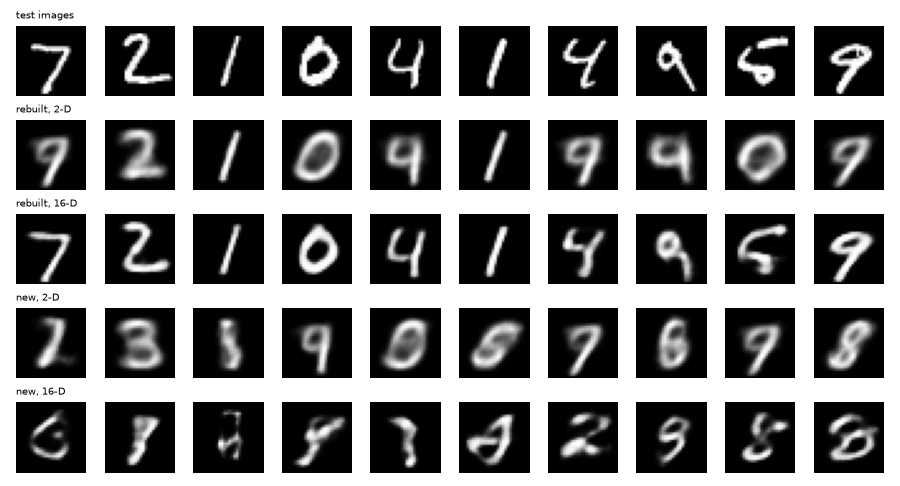

In [ ]:
from IPython.display import Image
Image('outputs/reconstructions_and_samples.png')

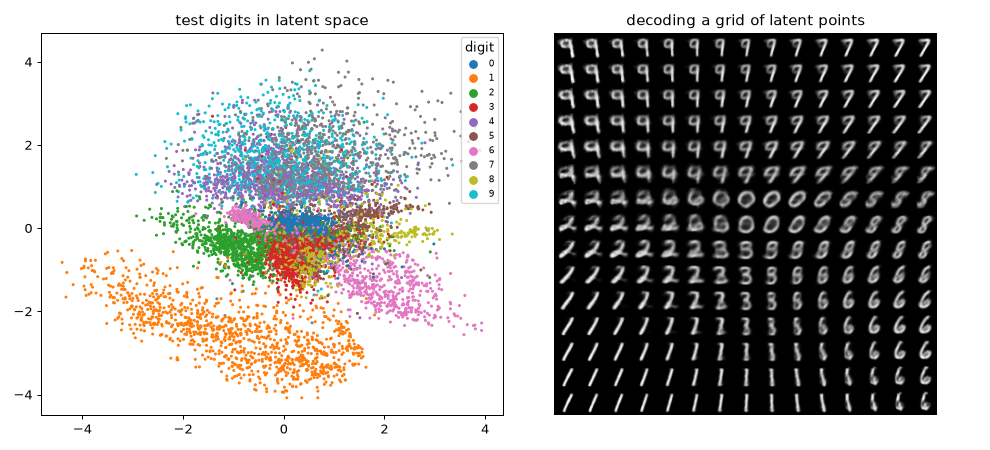

In [ ]:
from IPython.display import Image
Image('outputs/latent_map.png')

Three observations, each worth a sentence in your README:

1. **Reconstructions.** The 2-D model rebuilds blurry, averaged digits, and sometimes the wrong one (the 4s come back
   looking like 9s, the 5 like a 0). The 16-D model rebuilds them almost exactly.
2. **New digits.** Here the order reverses. The 2-D model's random samples are blurry but mostly recognizable. The 16-D
   model's are sharper but often scratchy and malformed. With 16 dimensions, the codes of the training digits don't
   fill the whole Gaussian prior, so random codes often land in "holes" the decoder never learned, a known weakness of
   VAEs discussed in section 19.2.
3. **The map.** In 2-D you can draw the latent space. Without ever seeing a label, the VAE put each digit in its own
   region: 51.6% of each digit's nearest neighbours are the same digit, against 10% by chance. The grid on the right
   shows the smooth transitions between them: walking across the space, a 9 becomes a 7, a 2 becomes an 8.

That's the VAE's trade-off: a small code generalizes and organizes, a large code remembers. Real systems use larger codes
with stronger decoders, and diffusion models (the next module) avoid the problem altogether.

## Step 5: write the README and publish

In [ ]:
%%writefile README.md
# Variational autoencoder for handwritten digits

A variational autoencoder written in PyTorch (MLP encoder and decoder, reparameterization trick, closed-form KL term),
trained on MNIST with a 2-D and a 16-D latent space, then explored: reconstructions, brand-new digits, and a map of the
2-D latent space.

![latent map](outputs/latent_map.png)

## Results (10,000 test digits, 10 epochs)

| latent size | test ELBO (nats per image) | reconstruction term | KL term |
|---|---|---|---|
| 2 | -156.5 | -150.8 | 5.6 |
| 16 | **-106.2** | -83.3 | 22.9 |

In the 2-D latent space, 51.6% of each test digit's 5 nearest neighbours are the same digit (10% by chance), although
the VAE never saw a label.

![samples](outputs/reconstructions_and_samples.png)

## Run it

```bash
pip install -r requirements.txt
python train.py --latent 2
python train.py --latent 16
python explore.py
```

## What I learned

- A VAE trades reconstruction against a KL term that keeps the codes close to the prior; the latent size moves that balance.
- A 2-D code reconstructs blurrily but organizes the digits into a smooth, readable map.
- A 16-D code reconstructs sharply, but its random samples are worse: random codes can fall in regions no training
  digit occupies.

Based on chapter 19 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "Variational autoencoder on MNIST with latent space map"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/mnist-vae.git
git push -u origin main
```

## Make it yours

- **The β knob.** Multiply the KL term by β = 0.5 or 4 and retrain the 16-D model. How do reconstructions, samples and
  the KL change?
- **Interpolation.** Encode two test digits, walk in a straight line between their codes in 10 steps, and decode each
  point. Do the in-between images look like digits?
- **Convolutions.** Replace the MLP encoder and decoder with small convolutional ones. Does the ELBO improve?
- **Fashion.** Train on Fashion-MNIST (your part 1 `data.py`). What does the 2-D map of clothes look like?

## On your CV

> **Variational autoencoder** (PyTorch): VAE on MNIST with reparameterization and closed-form KL; compared 2-D and 16-D
> latent spaces (test ELBO −156.5 vs −106.2 nats) and showed an unsupervised 2-D latent map where 51.6% of neighbours
> share a digit class (10% by chance). github.com/YOUR-USERNAME/mnist-vae

## Check yourself

- [ ] You can write the ELBO's two terms and say what each wants.
- [ ] You can explain why the reparameterization trick is needed for the encoder to learn.
- [ ] You can explain why the 16-D model reconstructs better but samples worse.